<a href="https://colab.research.google.com/github/leeknnn/viktoriiashkorubska-41/blob/master/lab_work_5/lab_work_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Завдання 2: Варіаційний ряд ---
Відсортовані опади: [38 41 43 44 47 47 48 50 60 70 78 88]


,абсолютна,відносна_%,накопичена
опади,,,
35-50,8,66.7,8
50-65,1,8.3,9
65-80,2,16.7,11
80-95,1,8.3,12



--- Завдання 3: Гістограми ---


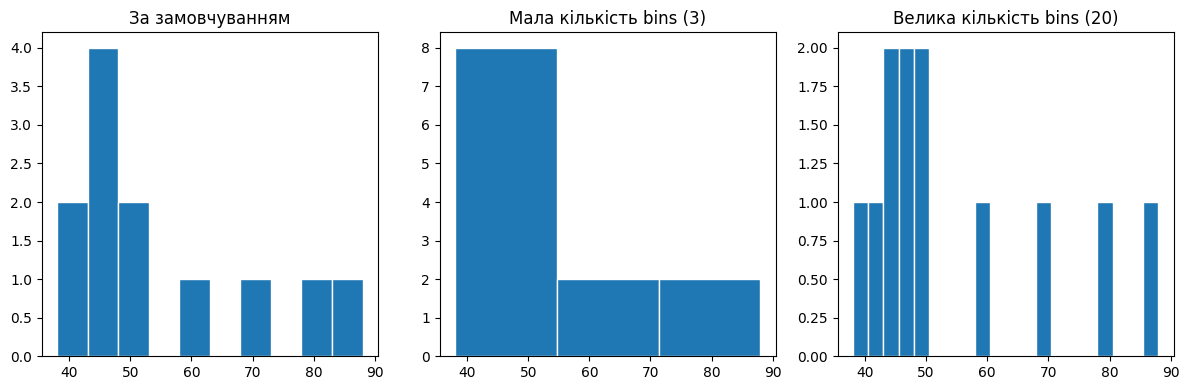


--- Завдання 4: Міри положення й квантилі ---
Середнє: 54.5
Медіана: 47.5
Мода: 47

Квантилі (Q1, медіана, Q3):
 0.25    43.75
0.50    47.50
0.75    62.50
dtype: float64


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер", "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]
precipitation = [47, 44, 38, 43, 60, 78, 88, 70, 48, 41, 47, 50]

df_precip = pd.DataFrame({
    "місяць": months,
    "опади": precipitation
})

print("--- Завдання 2: Варіаційний ряд ---")
sorted_precip = np.sort(df_precip["опади"].values)
print("Відсортовані опади:", sorted_precip)

bins = [35, 50, 65, 80, 95]
bin_labels = ["35-50", "50-65", "65-80", "80-95"]

categories = pd.cut(df_precip["опади"], bins=bins, labels=bin_labels, include_lowest=True)
abs_freq = categories.value_counts().sort_index()
rel_freq = (categories.value_counts(normalize=True).sort_index() * 100).round(1)
cum_freq = abs_freq.cumsum()

freq_table = pd.DataFrame({
    "абсолютна": abs_freq,
    "відносна_%": rel_freq,
    "накопичена": cum_freq
})
display(freq_table)

print("\n--- Завдання 3: Гістограми ---")
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.hist(df_precip["опади"], edgecolor="white")
plt.title("За замовчуванням")

plt.subplot(1, 3, 2)
plt.hist(df_precip["опади"], bins=3, edgecolor="white")
plt.title("Мала кількість bins (3)")

plt.subplot(1, 3, 3)
plt.hist(df_precip["опади"], bins=20, edgecolor="white")
plt.title("Велика кількість bins (20)")

plt.tight_layout()
plt.show()

print("\n--- Завдання 4: Міри положення й квантилі ---")
precip_series = pd.Series(precipitation)
mean_val = precip_series.mean()
median_val = precip_series.median()
mode_val = precip_series.mode()[0]

print(f"Середнє: {mean_val}")
print(f"Медіана: {median_val}")
print(f"Мода: {mode_val}")

quantiles = precip_series.quantile([0.25, 0.5, 0.75])
print("\nКвантилі (Q1, медіана, Q3):\n", quantiles)

## Відповіді на контрольні питання

1. **Чому середнє арифметичне некоректне для номінальної змінної «місто», навіть якщо завжди можна закодувати міста числами?**
   - Номінальна шкала фіксує лише назви категорій без жодного кількісного ранжування чи порядку (наприклад, Київ = 1, Львів = 2). Арифметичні операції (додавання, ділення) над цими умовними числами не мають жодного змісту, оскільки середнє значення між різними містами не відображає жодної реальної характеристики.

2. **Чому «номер місяця» — приклад, де класифікація за шкалою вимірювання не однозначна?**
   - З одного боку, номери місяців (1–12) мають фіксований порядок і рівні інтервали, що нагадує інтервальну шкалу. З іншого боку, тут немає абсолютного та природного нуля (нульовий місяць як відсутність часу не існує), а відлік є циклічним і умовним від початку календарного року, тому частіше цю шкалу відносять до порядкової.

3. **Чому для «кількості опадів» (де майже всі 12 значень різні) потрібна саме гістограма з розбиттям на інтервали, а не стовпчикова діаграма за окремими значеннями?**
   - Оскільки кількісні неперервні дані містять переважно унікальні значення, стовпчикова діаграма побудувала б окремий стовпець для кожної цифри з висотою «1», що не показало б загального розподілу. Гістограма групує значення в інтервали, дозволяючи наочно побачити частоту появи діапазонів опадів протягом року.

4. **Що означає накопичена частота на межі вашого третього інтервалу з Завдання 2?**
   - Накопичена частота для третього інтервалу показує сумарну кількість місяців у році (або загальну частку в%), у яких місячна кількість опадів не перевищує верхню межу цього третього інтервалу.